ADRIANA P. HERNANDEZ ROSA

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values before cleaning:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Missing values after cleaning:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Rows remaining: 342



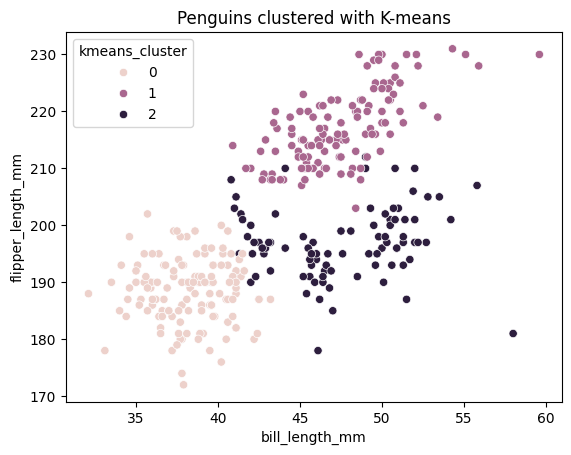

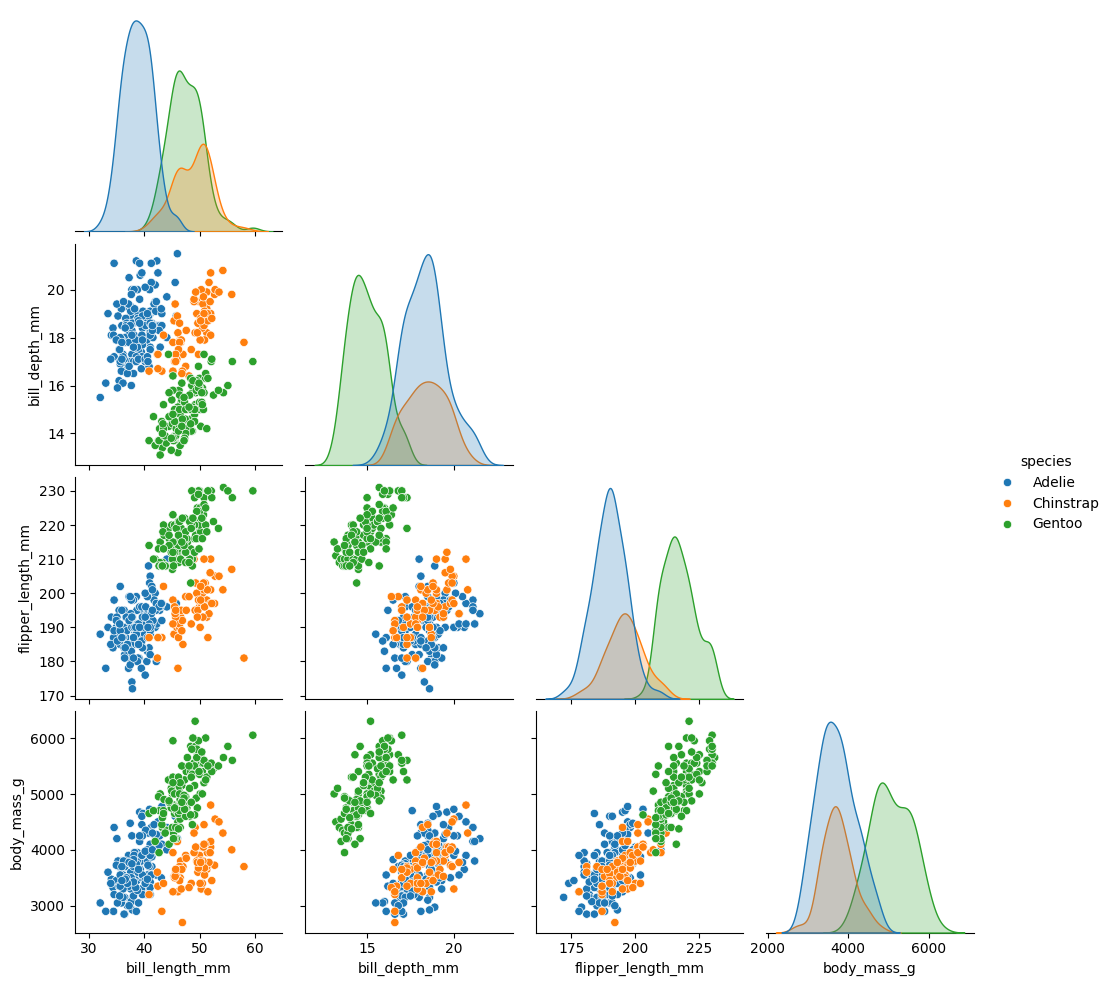

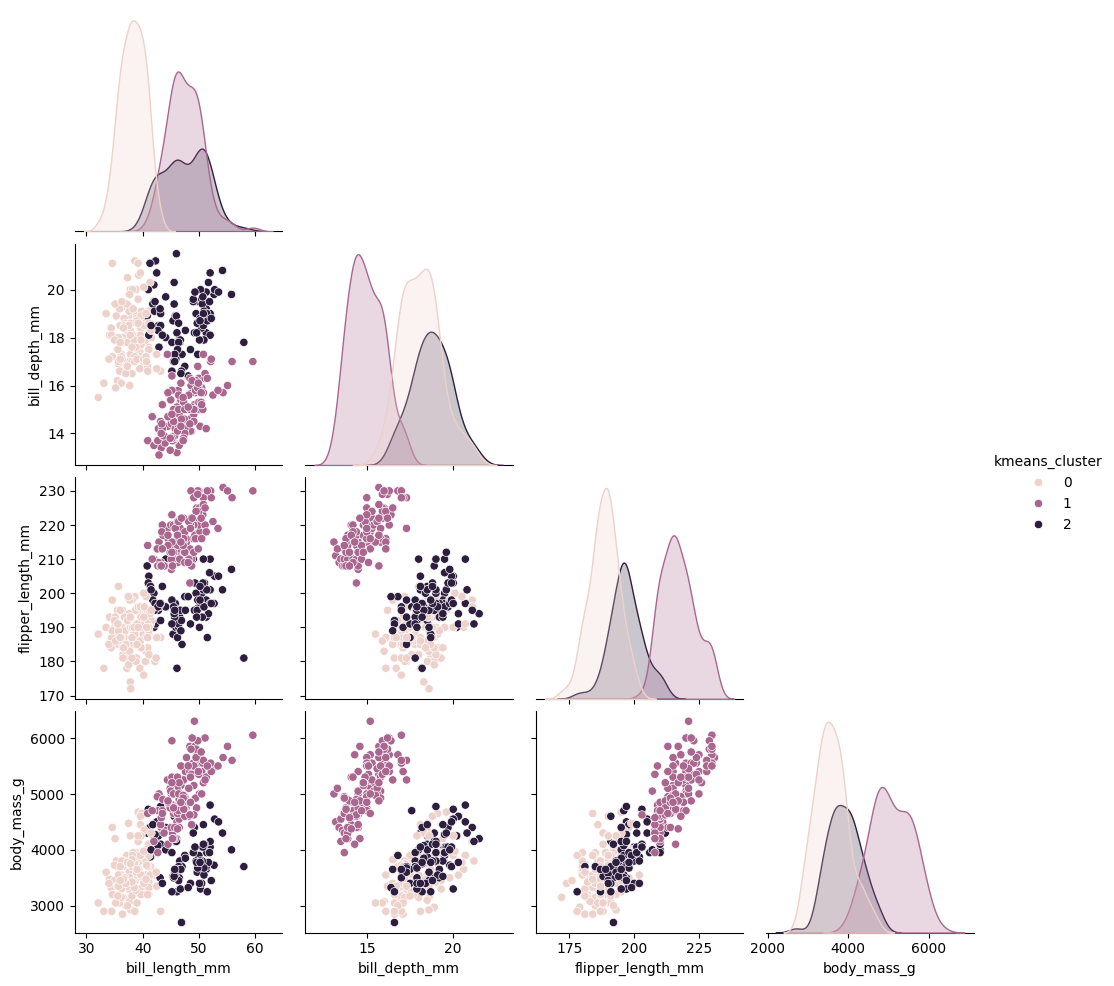


Species order: ['Adelie', 'Chinstrap', 'Gentoo']
[[127   0  24]
 [  5   0  63]
 [  0 123   0]]

Adjusted Rand score: 0.7928369051321087



In [29]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


# A) CHECK MISSING VALUES PER COLUMN, THEN "dropna()" AND CONFIRM THE DATA IS CLEAN

# Checking for missing values before deleting anything
print("Missing values before cleaning:")
print(penguins[num_cols].isna().sum())
print()
# Removing incomplete rows
penguins_clean = penguins[num_cols + ["species"]].dropna().copy()
# Confirm the data is clean
print("Missing values after cleaning:")
print(penguins_clean[num_cols].isna().sum())
print()
print("Rows remaining:", len(penguins_clean))
print()


# B) NORMALIZE THE NUMERIC COLUMNS WITH "StandardScaler"

# Creating the scaling tool
scaler = StandardScaler()
# Calculating the means and standard deviations of the columns and transforming measurements, and storing them
penguins_scaled_df = scaler.fit_transform(penguins_clean[num_cols])


# C) APPLY "KMeans" WITH "n_clusters=3" ON THE NORMALIZED DATA

# Asking the algorithm to make 3 clusters
# Using a ramdom number 13 as a seed
# Number of iterations used 10
kmeans_model = KMeans(n_clusters=3, random_state=13, n_init=10)
# Fitting the clustering model and assigns a cluster label to each penguin
kmeans_labels = kmeans_model.fit_predict(penguins_scaled_df)


# D) ADD "kmeans_labels" TO "penguins_clean", "plot bill_length_mm" VS "flipper_length_mm" COLORED BY CLUSTER,
#    AND MAKE 2 "pairplots (hue='species', hue=kmeans cluster)"

# Adding the labels to the unscaled data set
penguins_clean["kmeans_cluster"] = kmeans_labels
# Creating the requested scatterplot using the unscaled dataset:
# Length on the horizontal axis
# Flipper length on the vertical axis
# The hue parameter assigns colors according to cluster membership
sns.scatterplot(data=penguins_clean, x="bill_length_mm", y="flipper_length_mm", hue="kmeans_cluster")
plt.title("Penguins clustered with K-means")
plt.show()
print()
# Creating the pairplot using the real species
sns.pairplot(penguins_clean, vars=num_cols, hue="species", corner=True)
plt.show()
print()
# Creating the pairplot using the clusters
sns.pairplot(penguins_clean, vars=num_cols, hue="kmeans_cluster", corner=True)
plt.show()
print()


# E) CONFUSION MATRIX AND ADJUSTED "Rand score" VS "real 'species'"

# Encoding the species names as integers
encoder = LabelEncoder()
species_encoded = encoder.fit_transform(penguins_clean["species"])
# Calculating the confusion matrix
# Rows are the real species, in the printed order, and the columns are cluster IDs 0, 1, and 2
cm = confusion_matrix(species_encoded, kmeans_labels)
print("Species order:", list(encoder.classes_))
print(cm)
print()
# Calculating the Adjusted Rand Index (ARI)
ari = adjusted_rand_score(penguins_clean["species"], kmeans_labels)
print("Adjusted Rand score:", ari)
print()


Exercise 1 — Interpretation
- The first missing-value table is the check before cleaning: each of the four numerical features has 2 missing values. After dropna(), the second table shows 0 missing values in every feature, and 342 penguins remain.
- StandardScaler standardizes all four measurements (mean 0 and standard deviation 1), so body mass in grams does not dominate Euclidean distances simply because its raw numbers are larger.
- In the scatterplot and pairplots, Gentoo penguins form the clearest separate group, particularly because they tend to have longer flippers and greater body mass. Adelie and Chinstrap overlap more, so their clusters are harder to distinguish perfectly.
- The confusion matrix uses rows in species order ['Adelie', 'Chinstrap', 'Gentoo'] and columns for cluster IDs 0, 1, and 2:
  [[127, 0, 24], [5, 0, 63], [0, 123, 0]]. Thus, 123 Gentoo penguins are assigned to cluster 1; most Adelie penguins are assigned to cluster 0 (127), while most Chinstrap penguins are assigned to cluster 2 (63). Some Adelie and Chinstrap penguins are grouped together. Cluster IDs are arbitrary labels and do not intrinsically correspond to species.
- The Adjusted Rand Index (ARI) from this run is 0.7928369051321087 (about 0.793). This indicates good, but not perfect, agreement with the known species. ARI is 1 for a perfect match, around 0 for chance-level agreement, and can be negative for worse-than-chance agreement.
- The code only runs K-means on standardized features. Therefore, this run alone does not show whether normalization changed the result. To make that claim, compare it with a separate K-means model fitted to the raw numerical features.

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Missing Values? False
[[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]

5.656854249492381
5.656854249492381



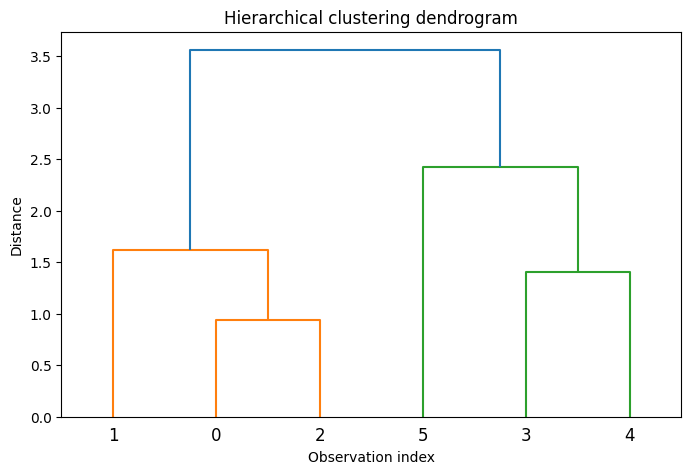


Agglomerative: [1 1 1 0 0 0]
K-means: [1 1 1 0 0 0]



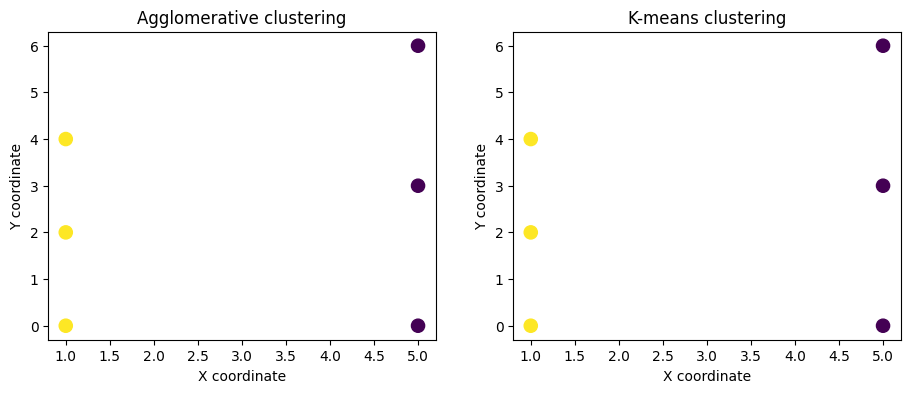


Agglomerative: {1: 3, 0: 3}
K-means: {1: 3, 0: 3}



In [30]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])


# A) CHECK FOR MISSING VALUES WITH `np.isnan(X).any()`

# `np.isnan(X).any()` checks whether at least one value is NaN
print("Missing Values?", np.isnan(X).any())


# B) NORMALIZE `X` WITH `StandardScaler`

# Same standardization from Exercise 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)
print()


# C) PLAIN-PYTHON `euclidean_distance` FUNCTION USING A `for loop` (no `numpy`/`sklearn`)

# Defining the fuction
def euclidean_distance(p1, p2):
# Starting the sum at 0
    total = 0
# Interating through each coordinate
    for i in range(len(p1)):
# Adding the squared difference to the running total
# Subtracting the corresponding coordinates and squaring the difference
        total += (p1[i] - p2[i]) ** 2
# Returning the square root of the total
    return total ** 0.5

# TEST THE FUCTION
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))
print()


# D) AGGLOMERATIVE CLUSTERING ON `X_scaled` + `dendrogram`

# Create 2 clusters
agglo_model = AgglomerativeClustering(n_clusters=2, linkage="ward")
# Return 1 cluster laber for each observation
agglo_labels = agglo_model.fit_predict(X_scaled)

# Calculating the hierarchinal merges
Z = linkage(X_scaled, method="ward")

# Drawing the dendogram
plt.figure(figsize=(8, 5))
dendrogram(Z, labels=[str(i) for i in range(len(X))])
plt.title("Hierarchical clustering dendrogram")
plt.xlabel("Observation index")
plt.ylabel("Distance")
plt.show()
print()


# E) K-MEANS CLUSTERING WITH `n_clusters=2` ON `X_scaled`

# Same as Exercise 1 (only with 2 clusters instead of 3)
kmeans_model = KMeans(n_clusters=2, random_state=13, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)


# F) COMPARE BOTH LABEL ARRAYS AND MAKE A SIDE-BY-SIDE SCARTTERPLOT

# Printing the arrays
print("Agglomerative:", agglo_labels)
print("K-means:", kmeans_labels)
print()

# Creating the side-by-side scatterplot
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
#Plotting agglomerative clustering
axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap="viridis", s=90)
axes[0].set_title("Agglomerative clustering")
axes[0].set_xlabel("X coordinate")
axes[0].set_ylabel("Y coordinate")
# Plotting K-means clustering
axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis", s=90)
axes[1].set_title("K-means clustering")
axes[1].set_xlabel("X coordinate")
axes[1].set_ylabel("Y coordinate")
# Displaying the plots
plt.show()
print()


# G) `cluster_sizes` FUNCTION USING A DICTIONARY
def cluster_sizes(labels):
# Empty dictionary
    counts = {}
# Looping through every cluster level
    for label in labels:
        label = int(label)
# If the label already exists, it increases the number by 1, otherwise add the label with a count of 1
        if label in counts:
            counts[label] += 1
        else:
            counts[label] = 1
# Return the completed dictionary
    return counts

print("Agglomerative:", cluster_sizes(agglo_labels))
print("K-means:", cluster_sizes(kmeans_labels))
print()

Exercise 2 — Interpretation
- The dataset contains no missing values. The Euclidean distance between the two most separated points is approximately 5.657, calculated using the Euclidean distance formula.
- The dendrogram shows two main clusters: observations 0, 1, and 2 form one group, while observations 3, 4, and 5 form the other. These groups merge at a relatively large distance, indicating that they are well separated.
- Both Agglomerative clustering and K-means produced the same labels: [1, 1, 1, 0, 0, 0]. Each algorithm assigned three observations to each cluster, as confirmed by the cluster counts {1: 3, 0: 3}.
- Overall, both methods identified the same two groups in this dataset. Although the cluster labels are arbitrary, the results show that both algorithms successfully separated the six points into the same groups.

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values before cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64

Missing values after cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64

Rows remaining: 1000



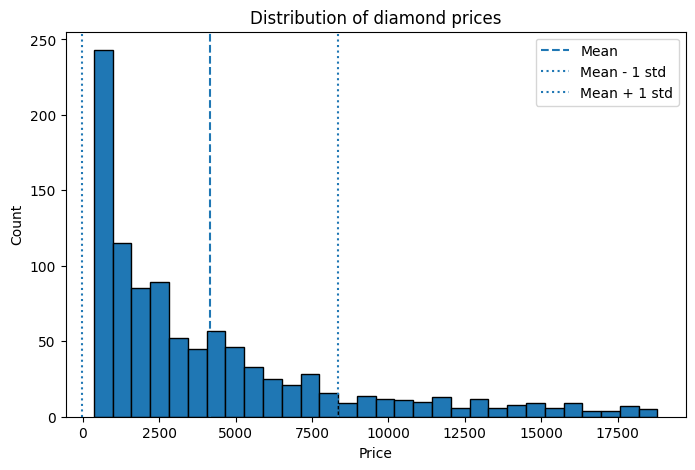

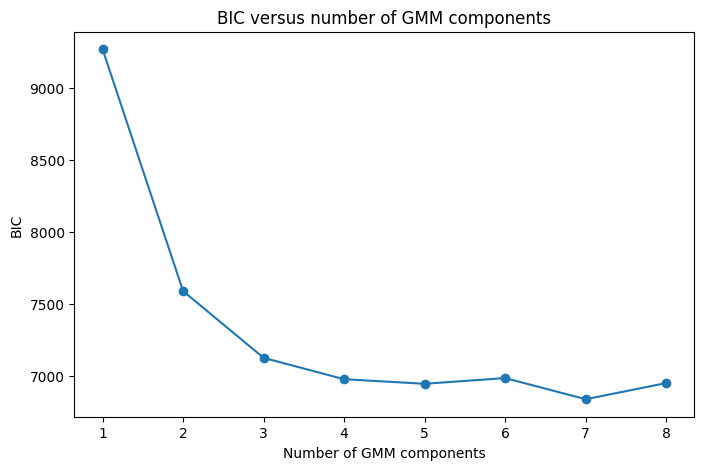


BIC scores: [np.float64(9270.10994236167), np.float64(7589.331368834791), np.float64(7125.397547722551), np.float64(6976.940330915988), np.float64(6945.346112026267), np.float64(6984.860286398627), np.float64(6837.980996050475), np.float64(6950.091738000957)]
Best number of components: 7



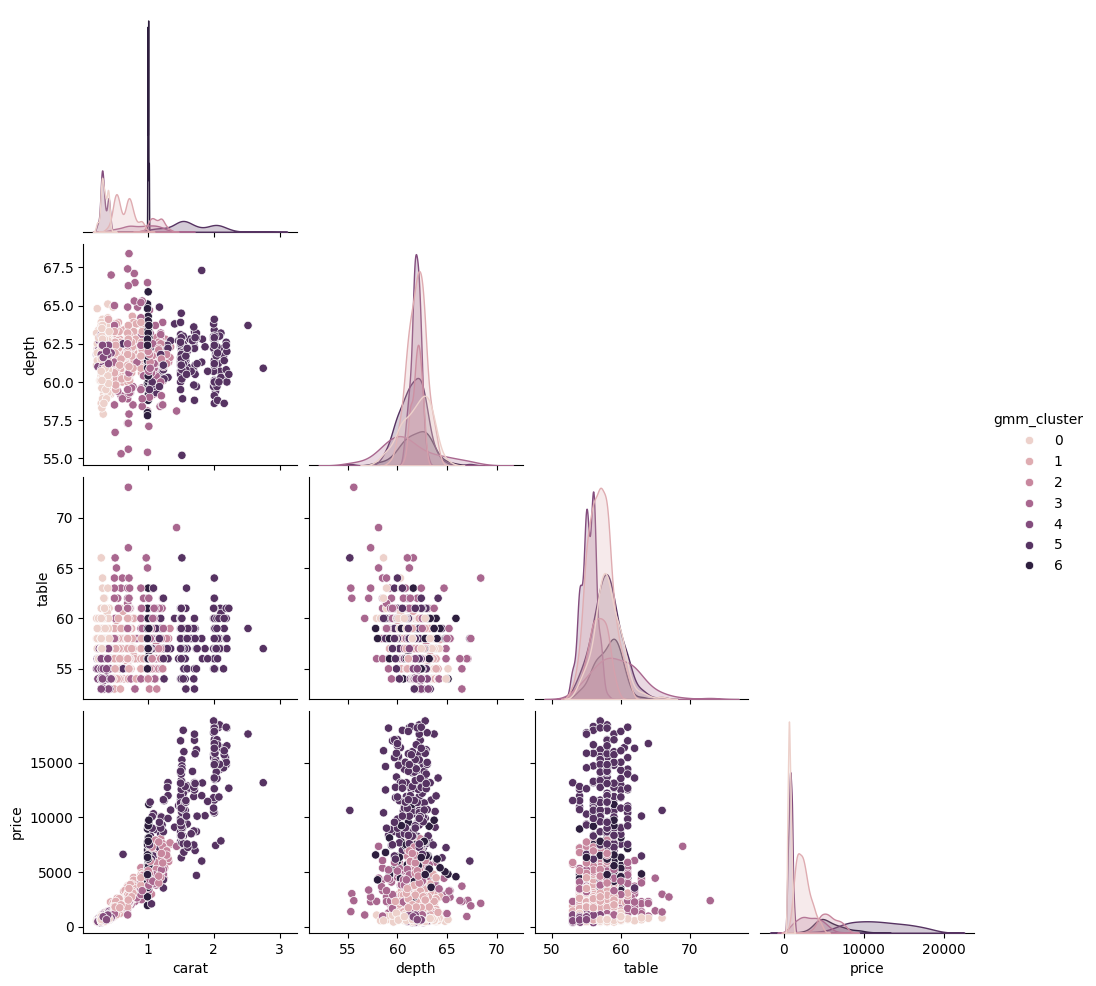

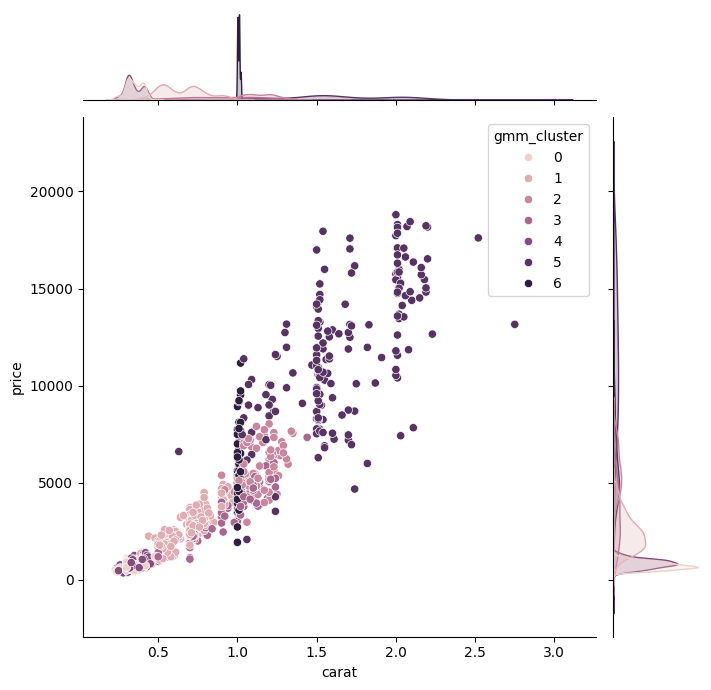

In [28]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)


# A) SELECT NUMERIC COLUMNS INTO `diamonds_num`, CHECK MISSING VALUES, `dropna()` AND CONFIRM IT'S CLEAN

# Using the 4 requested variables for the rows
num_cols = ["carat", "depth", "table", "price"]
# Checking for missing values
diamonds_num = diamonds[num_cols].copy()
print("Missing values before cleaning:")
print(diamonds_num.isna().sum())
print()
# Removing the missing values and dysplaying the clean data
diamonds_num = diamonds_num.dropna().copy()
print("Missing values after cleaning:")
print(diamonds_num.isna().sum())
print()
# Showing how many rows remain
print("Rows remaining:", len(diamonds_num))
print()


# B) HISTOGRAM OF "PRICE" WITH "MEAN" AND "MEAN +/-" STD LINES

# Calculating the average
price_mean = diamonds_num["price"].mean()
# Calculating the standard deviation
price_std = diamonds_num["price"].std()
# Creating the figure container for the histogram
plt.figure(figsize=(8, 5))
# Creating the histogram
plt.hist(diamonds_num["price"], bins=30, edgecolor="black")
# Adding the vertical reference lines
plt.axvline(price_mean, linestyle="--", label="Mean")
plt.axvline(price_mean - price_std, linestyle=":", label="Mean - 1 std")
plt.axvline(price_mean + price_std, linestyle=":", label="Mean + 1 std")
# Adding the axis labels and other elements
plt.xlabel("Price")
plt.ylabel("Count")
plt.title("Distribution of diamond prices")
plt.legend()
plt.show()
print()


# C) NORMALIZE THE 4 NUMERIC COLUMMNS WITH `StandardScaler`

# Same standardization from Exercise 1 & 2
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)


# D) FIT `GMM` FOR `n_components = 1..8` ON `diamonds_scaled`, STORE `BIC` VALUES, PLOT `BIC` VS `n_components`

# Creating an empty list to stare the BIC scores
bic = []
# Produces integers 1-8
n_components_range = range(1, 9)
# Loop creating a model with each candidate number of components
for n in n_components_range:
    model = mixture.GaussianMixture(n_components=n, random_state=13,n_init=3)
# Estimating mixture parameters
    model.fit(diamonds_scaled)
# Adding scores to the list
# Calculating the BIC for the fitted model
    bic.append(model.bic(diamonds_scaled))

# Plotting the scores
# Creating the figure container
plt.figure(figsize=(8, 5))
# Creating the plot diagram
plt.plot(list(n_components_range), bic, marker="o")
plt.xticks(list(n_components_range))
# Adding the axis labels and other elements
plt.xlabel("Number of GMM components")
plt.ylabel("BIC")
plt.title("BIC versus number of GMM components")
plt.show()
print()


# E) FIND THE NUMBER OF COMPONENTS THAT MINIMIZES BIC AND FIT THE FINAL GMM

# Giving the candidate component counts
# Returning the position of the smallest BIC score
best_n = list(n_components_range)[int(np.argmin(bic))]
print("BIC scores:", bic)
print("Best number of components:", best_n)
print()
# Creating the final model using the selected number of components
gmm_model = mixture.GaussianMixture(n_components=best_n, random_state=13, n_init=3)
# Assigning a cluster label to every diamond
gmm_labels = gmm_model.fit_predict(diamonds_scaled)


# F) ADD `gmm_labels` TO `diamonds_num` (unscaled) AND MAKE A `pairplot` + A `jointplot` (CARAT VS PRICE)

# Adding labels to the unscaled data
diamonds_num["gmm_cluster"] = gmm_labels
# Creating the `pairplot`
sns.pairplot(diamonds_num, vars=["carat", "depth", "table", "price"], hue="gmm_cluster", corner=True)
plt.show()
print()
# Creating the `jointplot`
sns.jointplot(data=diamonds_num, x="carat", y="price", hue="gmm_cluster", kind="scatter", height=7)
plt.show()
print()

Exercise 3 — Interpretation
- There are 1,000 rows in the sampled dataset, and the missing-value check reports zero missing values before and after cleaning.
- The histogram shows that diamond prices are strongly right-skewed: most sampled diamonds are at lower prices, with a long tail toward more expensive diamonds. This supports standardizing the four features before fitting the main GMM, because price is on a much larger numerical scale than depth and table.
- For the standardized features, the BIC scores reach their minimum at 7 components (BIC ≈ 6837.98). Since lower BIC is preferred among models fitted to the same representation, the 7-component model is selected from the tested range of 1–8.
- In the pairplot, clusters overlap substantially for depth and table, so these variables do not visually separate all groups clearly. Separation is more apparent along carat and price: some clusters contain smaller, lower-priced diamonds, while another group includes many larger, higher-priced diamonds. The jointplot shows the strong positive relationship between carat and price, but also shows overlap between clusters rather than clean boundaries.
- A GMM component is a fitted statistical distribution, not necessarily a distinct real-world category of diamond. Therefore, the BIC-selected count of 7 is a model-based choice, not proof that there are seven natural diamond types; the pairplot suggests that the groups are not all cleanly separated.
- The added raw-feature comparison prints the best component count for the raw features alongside the standardized count (7). Report the raw count printed by your run and say whether the selected counts differ. Treat this as exploratory: raw and standardized BIC values are not directly comparable, because rescaling changes the likelihood's density units. Compare the selected counts, not the absolute BIC values, and do not present this as a definitive model-selection test.